# Autoregressive baseline report

AMZN Level 10, 21 June 2012. Initial checks, validation tuning, structural validity, depth SSIM and interpretation.
The main benchmark uses training histories to initialise AR; only starting prices come from validation. The selected VAR(2)
still produces about 93% invalid snapshots and misses the SSIM target. The earlier observed-history experiment is retained separately.

Saved results display by default without raw CSVs or checkpoints. Set `RECOMPUTE_GRID = True` to rerun both validation protocols.
TimeGAN and final test evaluation are pending.

In [1]:
from pathlib import Path
import sys
import numpy as np, pandas as pd
from IPython.display import display, Image, Markdown, HTML

parents = [Path.cwd(), *Path.cwd().parents]
relative = Path("recognition/timegan_spagheddy7")
candidates = [p / relative for p in parents] + [p / "Project/2.7/PatternAnalysis-2026" / relative for p in parents]
project = next(p for p in [*parents, *candidates] if (p / "ar_report.py").is_file())
sys.path.insert(0, str(project))
from ar_report import load_report

RECOMPUTE_GRID = False
LAGS, RIDGES, SEEDS = [1, 2, 4], [1e-6, 1e-4, 1e-2], [42, 43, 44]
if RECOMPUTE_GRID:
    from tune_ar import run_grid
    run_grid(project.parents[2] / "LOBSTER_SampleFile_AMZN_2012-06-21_10", LAGS, RIDGES, SEEDS)
report = load_report(project)
assert (LAGS, RIDGES, SEEDS) == (report["config"]["lags"], report["config"]["ridges"], report["config"]["seeds"])
grid = pd.DataFrame(report["candidates"]).set_index("candidate")
original, selected = grid.loc[report["original_candidate"]], grid.loc[report["selected_candidate"]]
def figure(name, width=1050):
    display(Image(filename=str(project / "reports/ar" / report["figures"][name]["file"]), width=width))
def mean_sd(row, metric, scale=1, digits=4):
    return f"{row[metric + '_mean'] * scale:.{digits}f} ± {row[metric + '_sd'] * scale:.{digits}f}"
conditional = report["conditional_validation"]
conditional_grid = pd.DataFrame(conditional["candidates"]).set_index("candidate")

## 1. Main findings

Training histories initialise AR; validation supplies starting prices only. Means ± sample SD across seeds 42, 43 and 44.
Smaller is better except SSIM. SD measures generation randomness, not confidence across trading days. These are validation scores.

In [2]:
measures = [("invalid_rate", "Invalid snapshots (%)", 100), ("kl_spread", "Spread KL", 1),
            ("kl_mid_return", "Mid-return KL", 1), ("abs_return_acf_mae", "Absolute-return ACF error", 1), ("depth_ssim", "Depth SSIM", 1)]
comparison = [[label, mean_sd(original, key, scale), mean_sd(selected, key, scale)] for key, label, scale in measures]
display(pd.DataFrame(comparison, columns=["Validation measure", "Original VAR(1)", f"Selected VAR({int(selected.lags)})"]).set_index("Validation measure"))
improvement = 100 * (original.invalid_rate_mean - selected.invalid_rate_mean)
display(Markdown(f"Selected p = {int(selected.lags)}, ridge = {selected.ridge:g}. Invalid snapshots fall by {improvement:.2f} "
                 "percentage points. Return KL and SSIM improve, but spread KL and ACF error worsen. The validity difference is small; "
                 "selection does not establish a statistically reliable advantage."))

,Original VAR(1),Selected VAR(2)
Validation measure,,
Invalid snapshots (%),93.1491 ± 0.0969,93.0160 ± 0.0986
Spread KL,0.1583 ± 0.0062,0.1678 ± 0.0242
Mid-return KL,0.5523 ± 0.0141,0.5327 ± 0.0054
Absolute-return ACF error,0.0188 ± 0.0017,0.0295 ± 0.0015
Depth SSIM,0.1250 ± 0.0027,0.1512 ± 0.0020


Selected p = 2, ridge = 0.01. Invalid snapshots fall by 0.13 percentage points. Return KL and SSIM improve, but spread KL and ACF error worsen. The validity difference is small; selection does not establish a statistically reliable advantage.

## 2. Data and method

The 40 features are 20 price log returns and 20 log(1 + volume) values, scaled using training data only.
Chronological splits cover 70/15/15% of elapsed trading time. Each generated sequence contains 32 market updates, not 32 seconds.

$$
x_t = b + \sum_{k=1}^{p} A_k x_{t-k} + \varepsilon_t
$$

The coefficients minimise the squared prediction error plus a ridge penalty:

$$
\min_{A_1,\ldots,A_p,b}
\frac{1}{N}\sum_t\left\|x_t-b-\sum_{k=1}^{p}A_kx_{t-k}\right\|_2^2
+\lambda\sum_{k=1}^{p}\left\|A_k\right\|_F^2
$$

The model samples complete training residual vectors for noise. This retains simultaneous feature dependence, but does not enforce
valid price ladders or time-varying volatility. AR starts from randomly sampled training histories, then generates recursively.
The shared decoder reconstructs prices from each validation window's starting prices. No clipping, sorting, rounding or repair is applied.

In [3]:
splits = [(name, item["raw_rows"], item["feature_rows"], item["windows"]) for name, item in report["splits"].items()]
display(pd.DataFrame(splits, columns=["Split", "Raw states", "Feature rows", "32-update windows"]).set_index("Split"))
display(Markdown(f"Evaluation uses {report['validation_windows']:,} common validation windows: "
                 f"{report['snapshots_per_seed']:,} generated snapshots per seed. The first window lacks sufficient prior history "
                 "and is excluded for every candidate to keep the same windows in both protocols. Weights, residuals, scaling and histogram boundaries use training only. "
                 "The full-day audit reads test data; no test model scores or test-based choices are computed."))

,Raw states,Feature rows,32-update windows
Split,,,
train,176255,176254,5507
validation,34624,34623,1081
test,58869,58868,1839


Evaluation uses 1,080 common validation windows: 34,560 generated snapshots per seed. The first window lacks sufficient prior history and is excluded for every candidate to keep the same windows in both protocols. Weights, residuals, scaling and histogram boundaries use training only. The full-day audit reads test data; no test model scores or test-based choices are computed.

### Starting information for the main comparison

Both models may learn from training data. At generation time neither receives validation features, volumes or future values.
Only the common decoder receives the 20 starting prices. AR samples four-row training histories with seed + 10000 and uses the last
p rows, so all AR orders share the same sampled contexts. TimeGAN will generate feature windows from noise.

Both use the same 1,080 chronological windows, 32 updates, three seeds and training-only scaling. Generated sample i is compared with
real window i; no best-of-many matching, filtering or repairs. The saved comparison signature records the data, scaler, anchors, metric settings and protocol.

In [4]:
information = [("Learned parameters and scaling", "Training only", "Training only"),
               ("Initial feature history", "Random training history", "None; generate from noise"),
               ("Validation history or volumes", "Not supplied", "Not supplied"),
               ("Starting prices", "20 prices in common decoder", "Same 20 prices in common decoder"),
               ("Comparison futures", "Same 32-update validation windows", "Same 32-update validation windows")]
display(pd.DataFrame(information, columns=["Information", "AR", "TimeGAN (planned)"]).set_index("Information"))

,AR,TimeGAN (planned)
Information,,
Learned parameters and scaling,Training only,Training only
Initial feature history,Random training history,None; generate from noise
Validation history or volumes,Not supplied,Not supplied
Starting prices,20 prices in common decoder,Same 20 prices in common decoder
Comparison futures,Same 32-update validation windows,Same 32-update validation windows


## 3. Initial AR(1) fit and generation check

These preserved measurements concern the earlier 64-sequence training-context run. They establish that fitting, saving, reloading
and generation worked; they are separate from validation. Timings exclude loading, decoding, saving and plotting as specified below.

,Result
Initial measurement,
Training pairs,"176,253"
Coefficients,1640
Training one-step MSE (scaled),0.002189
Spectral radius,0.976224
CPU fit only (s),0.3274
Generated shape,"[64, 32, 40]"
Feature rollout only (s),0.005368
All decoded values finite,True
"Invalid snapshots, all levels",92.14%


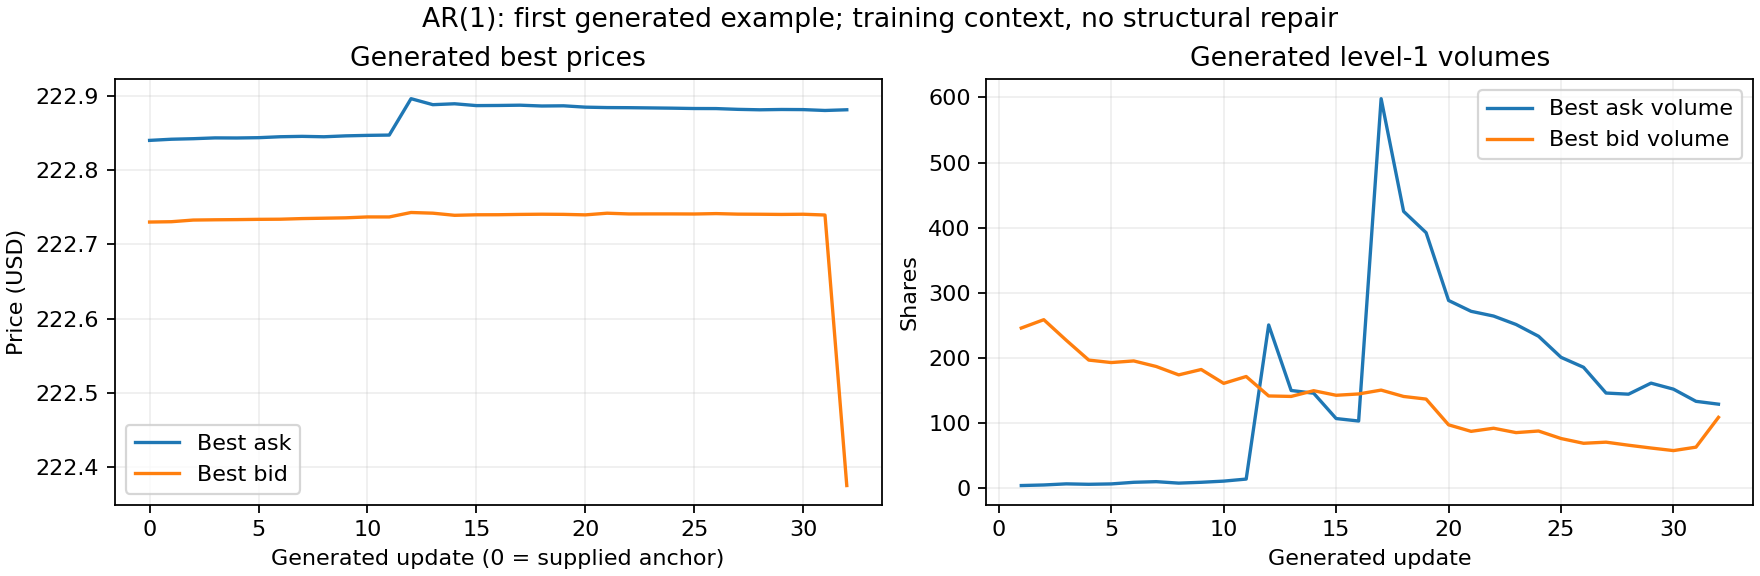

In [5]:
initial = report["initial_experiment"]
fit, generated = initial["fit"], initial["generation"]
facts = [("Training pairs", f"{fit['training_pairs']:,}"), ("Coefficients", fit["coefficient_count"]),
         ("Training one-step MSE (scaled)", f"{fit['training_one_step_mse_scaled']:.6f}"),
         ("Spectral radius", f"{fit['spectral_radius']:.6f}"), ("CPU fit only (s)", f"{fit['fit_seconds']:.4f}"),
         ("Generated shape", str(generated["generated_shape"])),
         ("Feature rollout only (s)", f"{generated['generation_seconds']:.6f}"),
         ("All decoded values finite", generated["all_decoded_values_finite"]),
         ("Invalid snapshots, all levels", f"{100 * initial['integrity']['invalid_rate']:.2f}%")]
display(pd.DataFrame(facts, columns=["Initial measurement", "Result"]).set_index("Initial measurement"))
figure("initial_preview")

The best-level lines can look plausible while deeper levels are unordered. A spectral radius below one describes stable linear mean
dynamics; it does not establish book validity. This historical run's invalid rate uses different contexts from the validation experiment.

## 4. Tuning grid

Nine fits: p = 1, 2, 4; ridge = 1e-6, 1e-4, 1e-2. Each uses seeds 42, 43, 44. Selection minimises mean invalid-book rate first,
then mean KL, then ACF error; p and ridge break any remaining ties. The selected configuration need not win on every measure.
SSIM is reported but does not affect selection. Models are fitted once and evaluated under both initial-information protocols.

,p,Ridge,Invalid (%),Spread KL,Return KL,ACF error,SSIM
0,2,1e-02,93.01601,0.16776,0.53271,0.02947,0.15124
1,1,1e-02,93.13947,0.14980,0.52616,0.02823,0.14746
2,4,1e-06,93.13947,0.13877,0.56498,0.02594,0.11651
3,1,1e-04,93.14911,0.15832,0.55226,0.01880,0.12497
4,2,1e-04,93.24942,0.16574,0.55669,0.02098,0.12286
5,4,1e-02,93.25424,0.16652,0.53796,0.02998,0.14466
6,4,1e-04,93.37191,0.15873,0.55929,0.01930,0.11814
7,2,1e-06,93.39988,0.14638,0.56287,0.02670,0.12130
8,1,1e-06,93.40856,0.15054,0.55806,0.02441,0.12279


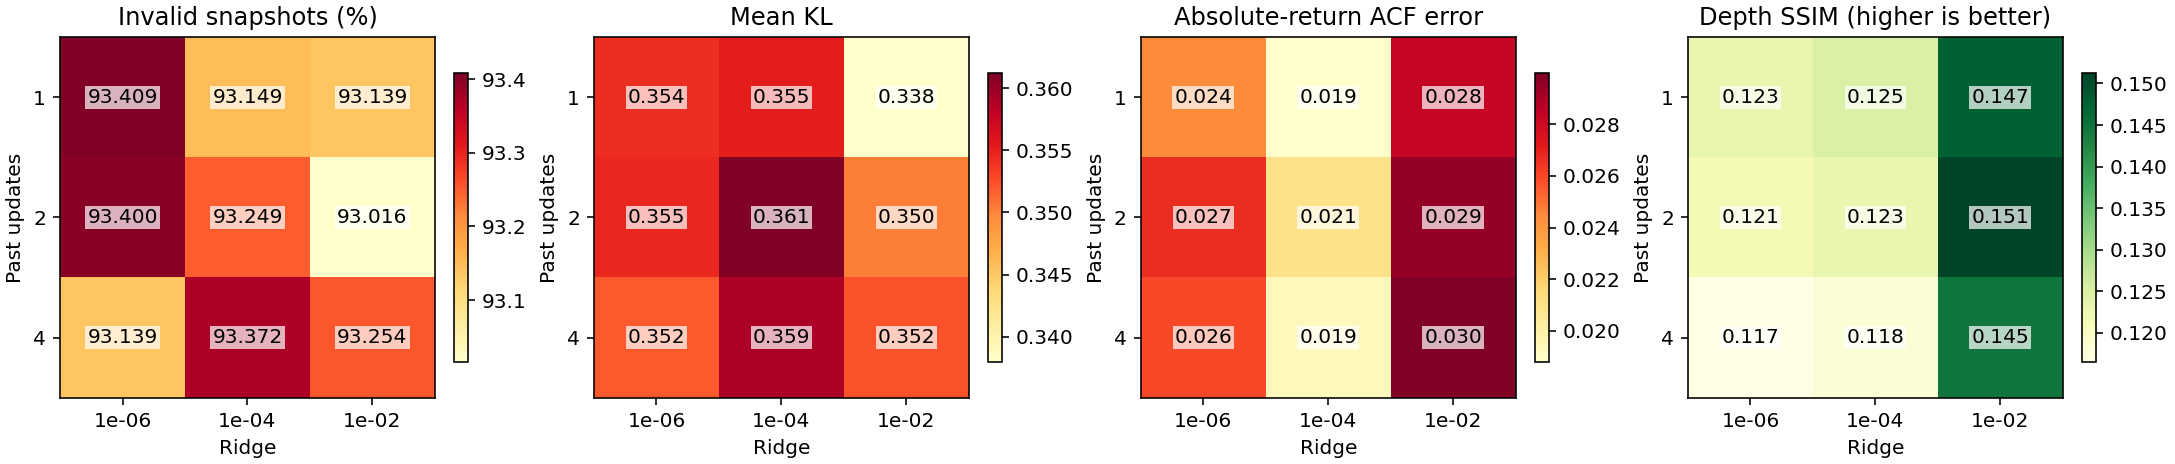

In [6]:
ranked = grid.sort_values(["invalid_rate_mean", "mean_kl_mean", "abs_return_acf_mae_mean"])
columns = {"lags": "p", "ridge": "Ridge", "invalid_rate_mean": "Invalid (%)", "kl_spread_mean": "Spread KL",
           "kl_mid_return_mean": "Return KL", "abs_return_acf_mae_mean": "ACF error", "depth_ssim_mean": "SSIM"}
table = ranked[list(columns)].rename(columns=columns).copy()
table["Invalid (%)"] *= 100
display(table.reset_index(drop=True).style.format({"p": "{:.0f}", "Ridge": "{:.0e}", **{c: "{:.5f}" for c in list(columns.values())[2:]}}))
figure("grid", width=1300)

## 5. Structural validity

A snapshot is invalid if any of its ten levels violates strict ask/bid ordering, positive prices, positive best spread, nonnegative
volume or finiteness. Categories overlap; do not add their percentages. Real validation snapshots pass all these checks.

In [7]:
checks = [("crossed_rate", "Nonpositive best spread"), ("ask_order_rate", "Unordered asks"),
          ("bid_order_rate", "Unordered bids"), ("negative_volume_rate", "Negative volume"),
          ("nonpositive_price_rate", "Nonpositive prices"), ("nonfinite_rate", "Non-finite values"),
          ("invalid_rate", "Any violation")]
rows = [[label, f"{100 * report['real_validity'][key]:.2f}", mean_sd(original, key, 100, 3), mean_sd(selected, key, 100, 3)]
        for key, label in checks]
display(pd.DataFrame(rows, columns=["Violation (%)", "Real", "Original", "Selected"]).set_index("Violation (%)"))

,Real,Original,Selected
Violation (%),,,
Nonpositive best spread,0.00,3.072 ± 0.405,4.204 ± 0.664
Unordered asks,0.00,83.364 ± 0.593,83.099 ± 0.405
Unordered bids,0.00,82.381 ± 0.444,82.514 ± 0.469
Negative volume,0.00,2.982 ± 0.270,0.392 ± 0.020
Nonpositive prices,0.00,0.000 ± 0.000,0.000 ± 0.000
Non-finite values,0.00,0.000 ± 0.000,0.000 ± 0.000
Any violation,0.00,93.149 ± 0.097,93.016 ± 0.099


## 6. Distributions and temporal behaviour

KL uses real || generated distributions, natural logs, 50 equally spaced training-range bins, two tail bins and 1e-8 probability
smoothing. All invalid finite books remain in the calculation. The plots show seed-mean histograms; reported KL is computed per seed first.

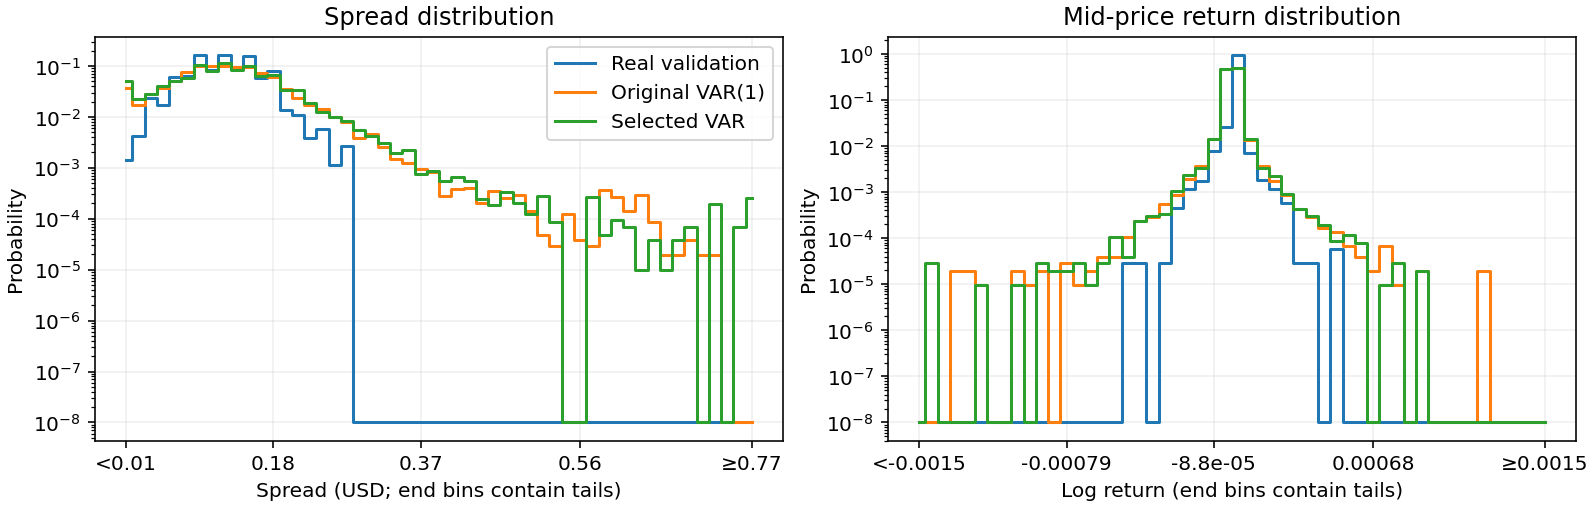

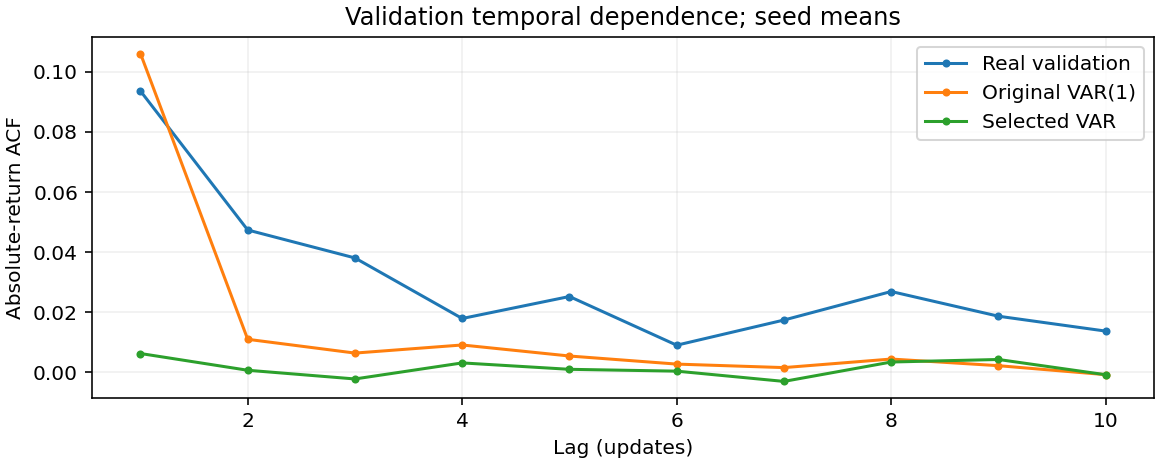

In [8]:
figure("distributions")
figure("acf", width=850)

The absolute-return ACF uses a global mean and the full squared-deviation sum as denominator, without pairs crossing window boundaries.
Error is mean absolute deviation from real ACF over lags 1–10. The selected model has higher ACF error than the original.
A 32-update analysis does not establish long-run volatility clustering or tail-risk fidelity.

## 7. Fixed example comparisons

First three eligible validation windows, first seed; selected before viewing results. Real and generated futures share starting prices,
but no validation history is given to the generator. A generated path is not a forecast of that particular realised future.
The line plots show the best level; the checks cover all ten.

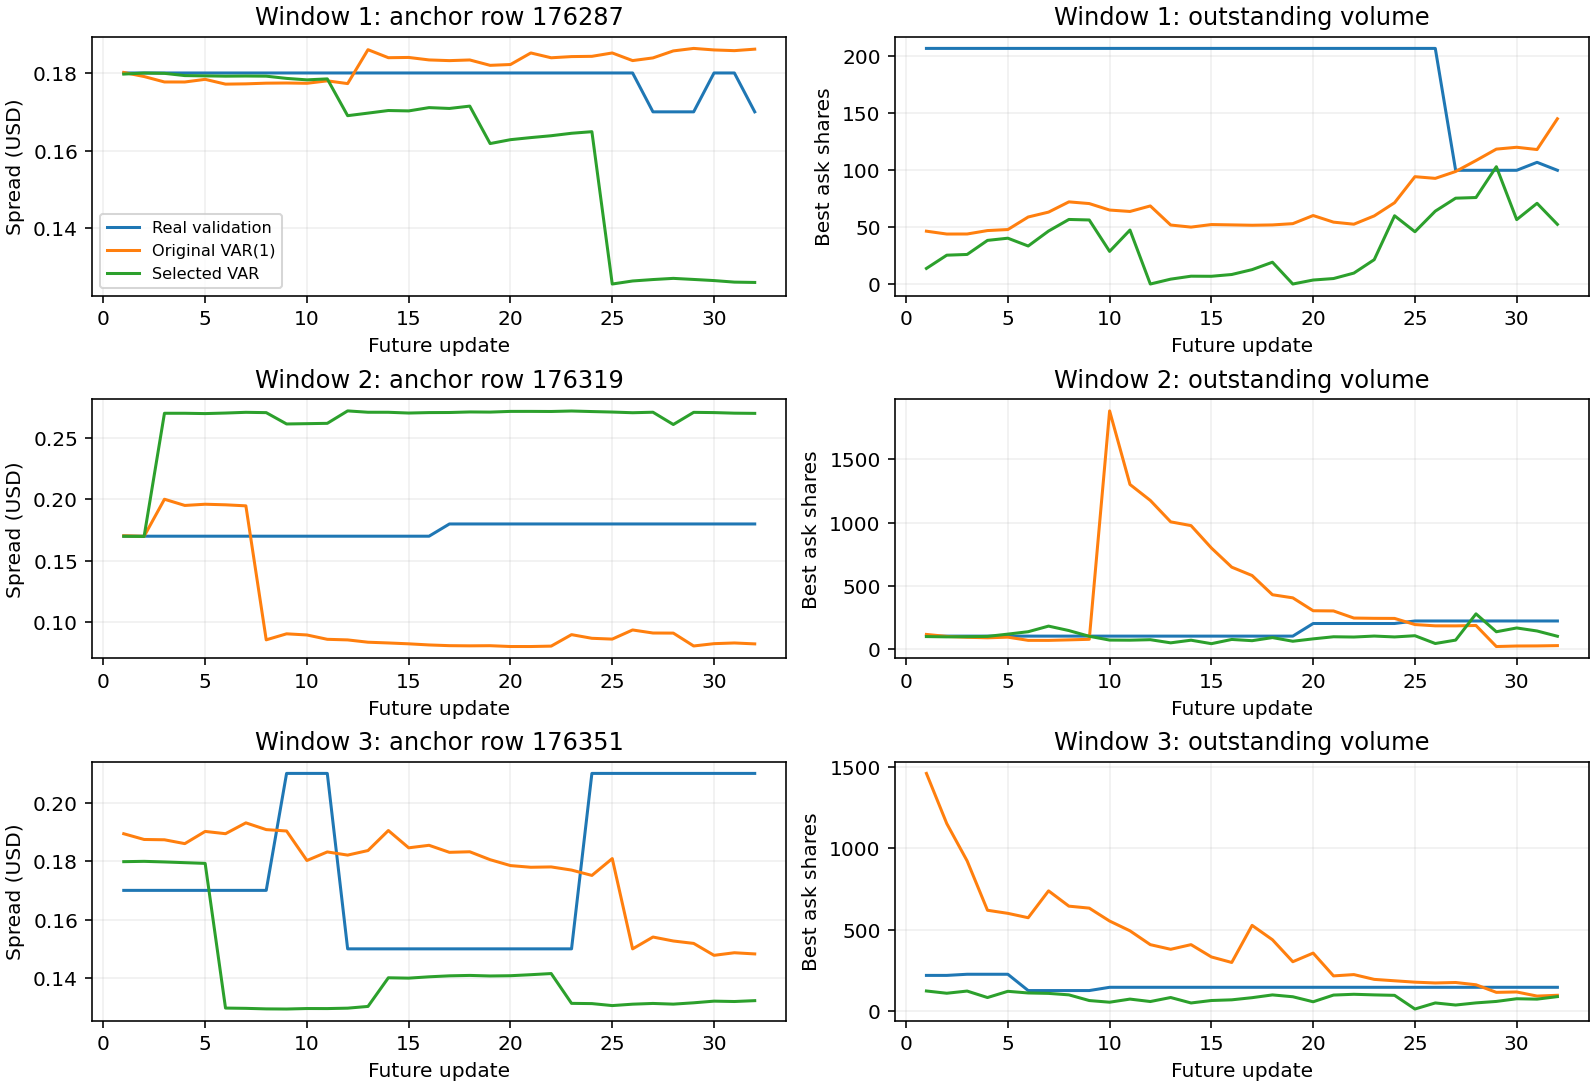

Window,Model,Invalid (%),Unordered asks (%),Unordered bids (%),Min spread ($),Depth SSIM
1,Real,0.000,0.000,0.000,0.170,1.000
1,Original,90.625,84.375,90.625,0.177,0.097
1,Selected,71.875,71.875,62.500,0.126,-0.022
2,Real,0.000,0.000,0.000,0.170,1.000
2,Original,96.875,15.625,96.875,0.080,-0.107
2,Selected,100.000,90.625,100.000,0.170,0.043
3,Real,0.000,0.000,0.000,0.150,1.000
3,Original,100.000,100.000,71.875,0.148,0.040
3,Selected,96.875,78.125,96.875,0.129,0.095


In [9]:
figure("examples")
examples = pd.DataFrame(report["example_diagnostics"])
columns = ["window", "model", "invalid_rate", "ask_order_rate", "bid_order_rate", "minimum_spread_usd", "depth_ssim"]
table = examples[columns].copy()
table[["invalid_rate", "ask_order_rate", "bid_order_rate"]] *= 100
table.columns = ["Window", "Model", "Invalid (%)", "Unordered asks (%)", "Unordered bids (%)", "Min spread ($)", "Depth SSIM"]
display(table.style.format({c: "{:.3f}" for c in table.columns[2:]}).hide(axis="index"))

Depth heatmaps share one colour scale. Rows are ask levels 10→1, then bid levels 1→10; signed log volume retains negative values.
SSIM uses the underlying numeric volume images with a fixed training scale, not these rendered colours. Volume similarity cannot
establish correctly ordered prices; the table above measures price-ladder failures separately.

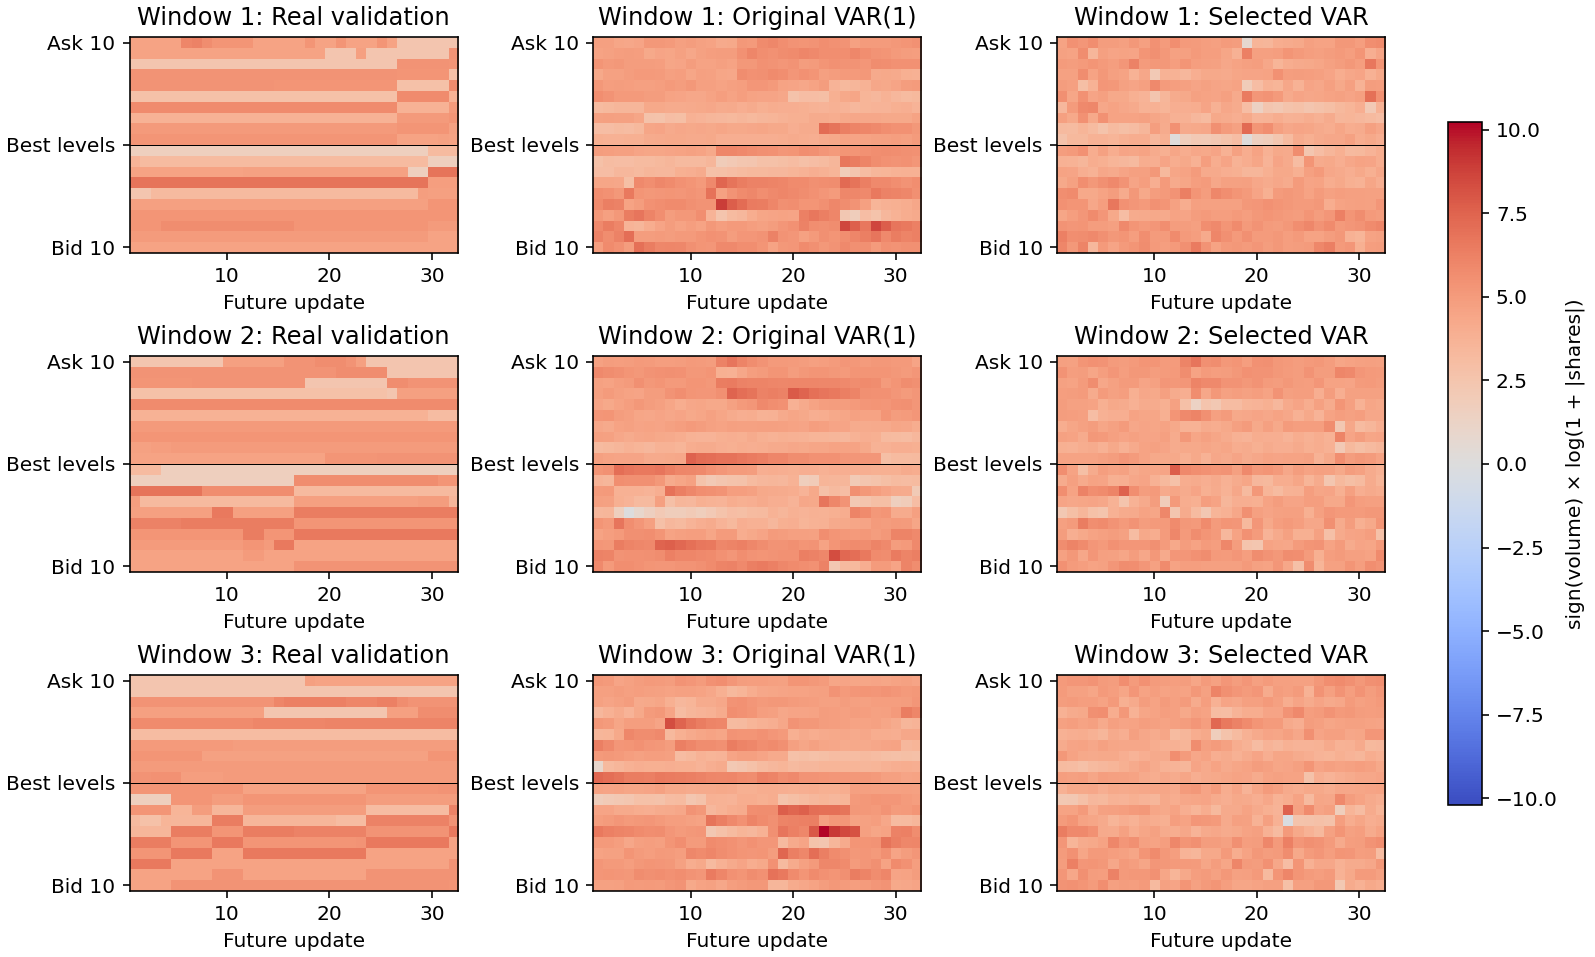

In [10]:
figure("depth")

## 8. Depth SSIM

Each sequence forms two numeric images: ten ask levels × 32 updates and ten bid levels × 32 updates. Transform volumes with
sign(v) × log(1 + |v|) / log(1 + maximum training volume). Training depths have nominal range [0, 1]; negative and larger values remain
unclipped, with data_range fixed at 1. There is no per-image normalisation.

For local 7×7 patches, compare their means, variances and covariance:

$$
\operatorname{SSIM}(x,y)=\frac{(2\mu_x\mu_y+C_1)(2\sigma_{xy}+C_2)}{(\mu_x^2+\mu_y^2+C_1)(\sigma_x^2+\sigma_y^2+C_2)}
$$

Use uniform weights, sample covariance, C₁ = 0.01² and C₂ = 0.03². Average patches wholly inside each image, then sides, sequences and seeds.
This declared variant follows the [SSIM equation](https://ece.uwaterloo.ca/~z70wang/publications/ssim.pdf) and
[uniform-window convention](https://scikit-image.org/docs/stable/api/skimage.metrics.html#skimage.metrics.structural_similarity);
it is not the original paper's 11×11 Gaussian setting. Higher is better; the project target is > 0.6 under this declared setup.

Identity should score 1. A fixed shuffle of real windows checks sensitivity to pairing, not an achievable ceiling or a model-selection criterion.
Even realistic independent samples need not match a particular future's depth image, so SSIM is only one diagnostic.

In [11]:
depth_measures = [("depth_ssim", "Both sides", 1), ("depth_ssim_ask", "Ask side", 1), ("depth_ssim_bid", "Bid side", 1),
                  ("depth_ssim_above_target_rate", "Sequences scoring > 0.6 (%)", 100)]
rows = [[label, mean_sd(original, key, scale), mean_sd(selected, key, scale)] for key, label, scale in depth_measures]
display(pd.DataFrame(rows, columns=["Depth measure", "Original", "Selected"]).set_index("Depth measure"))
controls = report["ssim_controls"]
print(f"Real versus itself: {controls['identity']:.4f}; real versus shuffled real: {controls['shuffled_real']:.4f} (seed {controls['shuffled_seed']}).")
display(Markdown("Both main AR configurations fall below the depth-similarity target. The shuffled-real score also shows that "
                 "pairing substantially affects this measure. A low SSIM alone does not establish an unrealistic distribution; "
                 "the independently measured price-ladder violations remain decisive failures."))

,Original,Selected
Depth measure,,
Both sides,0.1250 ± 0.0027,0.1512 ± 0.0020
Ask side,0.1286 ± 0.0013,0.1474 ± 0.0008
Bid side,0.1214 ± 0.0041,0.1551 ± 0.0032
Sequences scoring > 0.6 (%),0.0000 ± 0.0000,0.0000 ± 0.0000


Real versus itself: 1.0000; real versus shuffled real: 0.1122 (seed 2026).


Both main AR configurations fall below the depth-similarity target. The shuffled-real score also shows that pairing substantially affects this measure. A low SSIM alone does not establish an unrealistic distribution; the independently measured price-ladder violations remain decisive failures.

## 9. Fit, runtime and verification

Current fits use CPU float64 and four threads. Candidate fit times allocate one-third of each lag order's shared SVD time, then add
its ridge solve and residual calculation. Generation timing covers feature rollout only. GPU training memory was not measured.
One-step MSE is a separate teacher-forced diagnostic using observed past features, not an anchor-only generation score.

The refactor benchmark below is historical: one observed-history grid without SSIM. It is not a timing comparison against the new
two-protocol evaluation. Metric tests check identity, constant images and independent patch statistics; protocol tests check training-only priors.

In [12]:
resources = []
for label, row in [("Original", original), ("Selected", selected)]:
    resources.append([label, int(row.coefficient_count), row.training_one_step_mse, row.validation_one_step_mse,
                      row.spectral_radius, row.fit_seconds, row.generation_seconds_mean,
                      report["validation_windows"] / row.generation_seconds_mean])
display(pd.DataFrame(resources, columns=["Model", "Coefficients", "Train MSE", "Teacher-forced val MSE", "Radius",
                                      "Fit share (s)", "Rollout (s)", "Sequences/s"]).set_index("Model").round(6))
verification = report["refactor_verification"]
benchmark = verification["benchmark"]
before, after = benchmark["before_median"], benchmark["after_median"]
display(pd.DataFrame([["Historical single grid", before["wall_seconds"], after["wall_seconds"]],
                      ["Historical fitting", before["fit_seconds"], after["fit_seconds"]]],
                     columns=["Median of 3 runs (s)", "Before refactor", "After refactor"]).set_index("Median of 3 runs (s)").round(3))
display(Markdown(f"The earlier grid was {100 * (1 - after['wall_seconds'] / before['wall_seconds']):.1f}% faster in this comparison. "
                 "Both versions include data loading and saving but exclude interpreter startup and plotting. "
                 "The new implementation shares three SVDs instead of nine, decodes batches together and caches real validation statistics."))
print(f"Historical refactor checks: {verification['tests_passed']} passed. Same selected candidate: {verification['same_selection']}.")
print(f"Largest measured metric change: {max(verification['maximum_metric_changes'].values()):.2e}.")

,Coefficients,Train MSE,Teacher-forced val MSE,Radius,Fit share (s),Rollout (s),Sequences/s
Model,,,,,,,
Original,1640,0.002189,0.001712,0.976224,0.476361,0.090175,11976.672117
Selected,3240,0.002589,0.002360,0.906636,0.657071,0.172061,6276.835169


,Before refactor,After refactor
Median of 3 runs (s),,
Historical single grid,11.563,7.794
Historical fitting,5.077,2.435


The earlier grid was 32.6% faster in this comparison. Both versions include data loading and saving but exclude interpreter startup and plotting. The new implementation shares three SVDs instead of nine, decodes batches together and caches real validation statistics.

Historical refactor checks: 20 passed. Same selected candidate: True.
Largest measured metric change: 1.32e-14.


## 10. Why the earlier AR results differ

The earlier experiment gave AR the actual validation feature history before each rollout. Its selected VAR(4), ridge 1e-6, still
scores 91.38% invalid snapshots. All 27 earlier validity, KL and ACF evaluations reproduced exactly when adding SSIM.

This table holds fitted coefficients and innovation seeds fixed and changes the initial history. Compare the same model across protocols
to see that effect. Each protocol's selected model can differ. The observed-history scores are supplementary and must not be used as
the headline comparison against a TimeGAN that generates from noise without those observations.

In [13]:
keys = list(dict.fromkeys([report["original_candidate"], report["selected_candidate"], conditional["selected_candidate"]]))
rows = []
for key in keys:
    for label, results in [("Training history (main)", grid), ("Observed history (separate)", conditional_grid)]:
        row = results.loc[key]
        rows.append([key, label, 100 * row.invalid_rate_mean, row.kl_spread_mean, row.kl_mid_return_mean, row.depth_ssim_mean])
display(pd.DataFrame(rows, columns=["Model", "Initial history", "Invalid (%)", "Spread KL", "Return KL", "SSIM"]).round(4))
print("Main selection:", report["selected_candidate"], "| Observed-history selection:", conditional["selected_candidate"])

,Model,Initial history,Invalid (%),Spread KL,Return KL,SSIM
0,p1_ridge0.0001,Training history (main),93.1491,0.1583,0.5523,0.1250
1,p1_ridge0.0001,Observed history (separate),92.9244,0.1510,0.6058,0.2323
2,p2_ridge0.01,Training history (main),93.0160,0.1678,0.5327,0.1512
3,p2_ridge0.01,Observed history (separate),93.0064,0.1671,0.5651,0.1975
4,p4_ridge1e-06,Training history (main),93.1395,0.1388,0.5650,0.1165
5,p4_ridge1e-06,Observed history (separate),91.3802,0.1323,0.5913,0.2623


Main selection: p2_ridge0.01 | Observed-history selection: p4_ridge1e-06


## 11. Conclusion and remaining comparison work

Keep the original and selected AR models as benchmarks. With training-only initial histories, the selected model has marginally fewer
invalid snapshots and higher SSIM, but still fails the main validity and similarity targets. Tuning does not solve the unconstrained
price ladders. The earlier observed-history VAR(4) result answers a different conditional-generation question.

Use the saved `anchor_only_v1` information contract, validation windows, seeds, scaler and metric definitions for TimeGAN.
Generate its features from noise and apply the same starting-price decoder. Choose models on validation, then evaluate test once choices are fixed.

In [14]:
status = [("Zero invalid snapshots", "Not met" if selected.invalid_rate_mean > 0 else "Met"),
          ("Spread KL ≤ 0.1", "Not met" if selected.kl_spread_mean > 0.1 else "Met"),
          ("Mid-return KL ≤ 0.1", "Not met" if selected.kl_mid_return_mean > 0.1 else "Met"),
          ("Depth SSIM > 0.6", "Met" if selected.depth_ssim_mean > 0.6 else "Not met"), ("TimeGAN comparison", "Pending"), ("Final test evaluation", "Pending")]
display(pd.DataFrame(status, columns=["Criterion", "Selected baseline"]).set_index("Criterion"))

,Selected baseline
Criterion,
Zero invalid snapshots,Not met
Spread KL ≤ 0.1,Not met
Mid-return KL ≤ 0.1,Not met
Depth SSIM > 0.6,Not met
TimeGAN comparison,Pending
Final test evaluation,Pending


This is one stock on one trading day, with observed anchors and event-time sequences. It does not test cross-day generalisation,
event-arrival times or a market simulator that also generates starting prices. Pointwise SSIM depends on the fixed pairing and
is not a distributional test; use it alongside validity, KL, temporal diagnostics and failure examples.

## Appendix: complete seed results and reproducibility

All historical and current numeric results are in `reports/ar/results.json`; figures sit alongside it. The notebook embeds displayed
outputs and can rerun from that bundle without raw data, weights or ignored preview arrays. Recomputing requires the external dataset.
Model weights and larger generated arrays remain under ignored `outputs/`. The report checks source and figure hashes on load.

In [15]:
fields = ["candidate", "seed", "status", "invalid_rate", "kl_spread", "kl_mid_return", "abs_return_acf_mae", "depth_ssim"]
for title, experiment in [("Main: training histories", report), ("Separate: observed validation histories", conditional)]:
    runs = pd.DataFrame(experiment["runs"])
    display(HTML(f"<details><summary>{title}: all 27 seed evaluations</summary>" + runs[fields].to_html(index=False, float_format=lambda x: f"{x:.6f}") + "</details>"))
files = pd.DataFrame(report["input_files"])[["name", "bytes", "sha256"]]
display(HTML("<details><summary>Input provenance</summary>" + files.to_html(index=False) + "</details>"))
print(f"PyTorch {report['torch_version']}; NumPy {report['numpy_version']}; SciPy {report['scipy_version']}; seeds {SEEDS}.")
print(f"Protocol: {report['protocol_id']}; test evaluated: {report['test_evaluated']}.")
print("Comparison contract SHA256:", report["comparison_signature"])

candidate,seed,status,invalid_rate,kl_spread,kl_mid_return,abs_return_acf_mae,depth_ssim
p1_ridge1e-06,42,ok,0.933883,0.144510,0.571430,0.023677,0.125918
p1_ridge1e-06,43,ok,0.932205,0.154513,0.548431,0.027142,0.120772
p1_ridge1e-06,44,ok,0.936169,0.152591,0.554318,0.022416,0.121673
p1_ridge0.0001,42,ok,0.931684,0.154640,0.567640,0.018130,0.128041
p1_ridge0.0001,43,ok,0.930440,0.165479,0.539881,0.020772,0.122954
p1_ridge0.0001,44,ok,0.932350,0.154828,0.549252,0.017505,0.123910
p1_ridge0.01,42,ok,0.930787,0.143533,0.529468,0.028160,0.148451
p1_ridge0.01,43,ok,0.930498,0.155776,0.523382,0.029122,0.146556
p1_ridge0.01,44,ok,0.932899,0.150091,0.525635,0.027415,0.147377
p2_ridge1e-06,42,ok,0.933478,0.158748,0.566514,0.024088,0.122671


candidate,seed,status,invalid_rate,kl_spread,kl_mid_return,abs_return_acf_mae,depth_ssim
p1_ridge1e-06,42,ok,0.926881,0.137223,0.622631,0.023852,0.236588
p1_ridge1e-06,43,ok,0.924740,0.145246,0.596139,0.027189,0.231732
p1_ridge1e-06,44,ok,0.927836,0.140287,0.604617,0.022362,0.235851
p1_ridge0.0001,42,ok,0.929572,0.149591,0.622570,0.018257,0.234046
p1_ridge0.0001,43,ok,0.928588,0.155228,0.595055,0.020734,0.229464
p1_ridge0.0001,44,ok,0.929572,0.148214,0.599805,0.017453,0.233321
p1_ridge0.01,42,ok,0.931655,0.142348,0.544869,0.028176,0.161877
p1_ridge0.01,43,ok,0.929745,0.154127,0.538894,0.029121,0.159971
p1_ridge0.01,44,ok,0.931597,0.150873,0.537980,0.027443,0.160746
p2_ridge1e-06,42,ok,0.923987,0.156452,0.598714,0.024305,0.256797


name,bytes,sha256
AMZN_2012-06-21_34200000_57600000_message_10.csv,11248750,c85a75b51f3616a683f825c2e03f984535e9329a8be5ab12325130d32223a2c5
AMZN_2012-06-21_34200000_57600000_orderbook_10.csv,63216242,decfe952b3fa06c9922dc8fba763a37a0fb032d4231767997e4abf2aa0d29b50


PyTorch 2.8.0+cu128; NumPy 2.2.6; SciPy 1.16.3; seeds [42, 43, 44].
Protocol: anchor_only_v1; test evaluated: False.
Comparison contract SHA256: e52140139de3081e194ba3224d3578d13f70173f3d8eae0bd81641cbeac3e6a5
